# Predicting Coral Reef Regimes


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay, mean_squared_error
from sklearn.decomposition import PCA

SEED = 47
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)

Python: 3.13.16 | scikit-learn: 1.6.1


## 1. Load the original data


In [2]:
DATA_URL = "https://raw.githubusercontent.com/salliewalecka/Hawaii_RegimesPredictors/master/Data/Hawaii_RegimesPredictors.txt"
print("Loading dataset from:", DATA_URL)
try:
    df = pd.read_csv(DATA_URL, sep="\t", decimal=",")
except Exception as exc:
    raise RuntimeError(
        "Could not download the dataset. Check your internet connection "
        "and that DATA_URL is accessible, then rerun this cell."
    ) from exc

FEATURES = list(df.loc[:, "Effluent":"Depth"].columns)
assert len(df) == 620 and len(FEATURES) == 20, "Unexpected dataset size or predictors"
assert set(df.Regime) == {1, 2, 3, 5}, "Unexpected regime labels"
X = df[FEATURES].astype(float)
y = df.Regime.astype(int)
print("Rows:", len(df), "| Predictors:", len(FEATURES))
display(df.head())
display(X.isna().sum().loc[lambda s: s > 0].rename("Missing values"))

Loading dataset from: https://raw.githubusercontent.com/salliewalecka/Hawaii_RegimesPredictors/master/Data/Hawaii_RegimesPredictors.txt
Rows: 620 | Predictors: 20


,id_spatial,Long,Lat,Island,Coral,CCA,Turf,Macro,Other,Grazers,...,PAR_STD,WAV_CLIM_M,WAV_ANOM_F,Complexity,Depth,Regime,Regime1,Regime2,Regime3,Regime5
0,4,-157.307727,21.106717,Molokai,1.023891,1.706485,77.815700,18.088737,1.023891,1.324986,...,8.5628,36.542160,0.083878,4.889608,2.8000,1,1,0,0,0
1,5,-157.304986,21.113497,Molokai,3.555556,1.333333,83.555556,9.777778,0.888889,0.890407,...,8.5628,36.542160,0.083878,3.793523,7.3152,1,1,0,0,0
2,6,-157.303306,21.124814,Molokai,17.620555,6.348836,44.875760,25.716525,4.836712,4.628477,...,9.4296,38.007866,0.084089,5.275938,11.5000,2,0,1,0,0
3,8,-157.299938,21.148297,Molokai,0.675676,1.351351,86.486487,0.337838,5.743243,0.069128,...,9.4296,39.139775,0.087039,2.511288,29.1000,1,1,0,0,0
4,9,-157.300286,21.128897,Molokai,4.000000,3.111111,53.333333,17.333333,21.777778,11.775000,...,9.4296,40.587803,0.084932,6.865359,10.0584,2,0,1,0,0


,Missing values
Complexity,113
Depth,12


## 2. Hold out the test set and explore training data


Training: (496, 20) | Test: (124, 20)


,Training class counts
Regime,
1,127
2,135
3,118
5,116


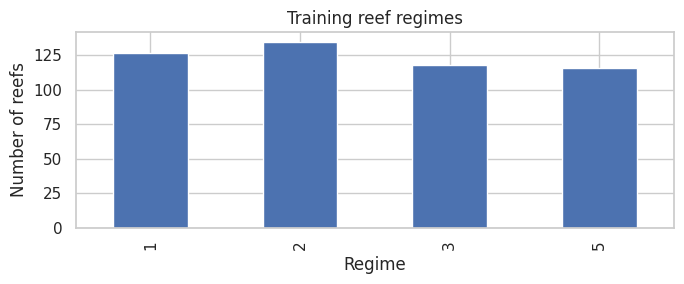

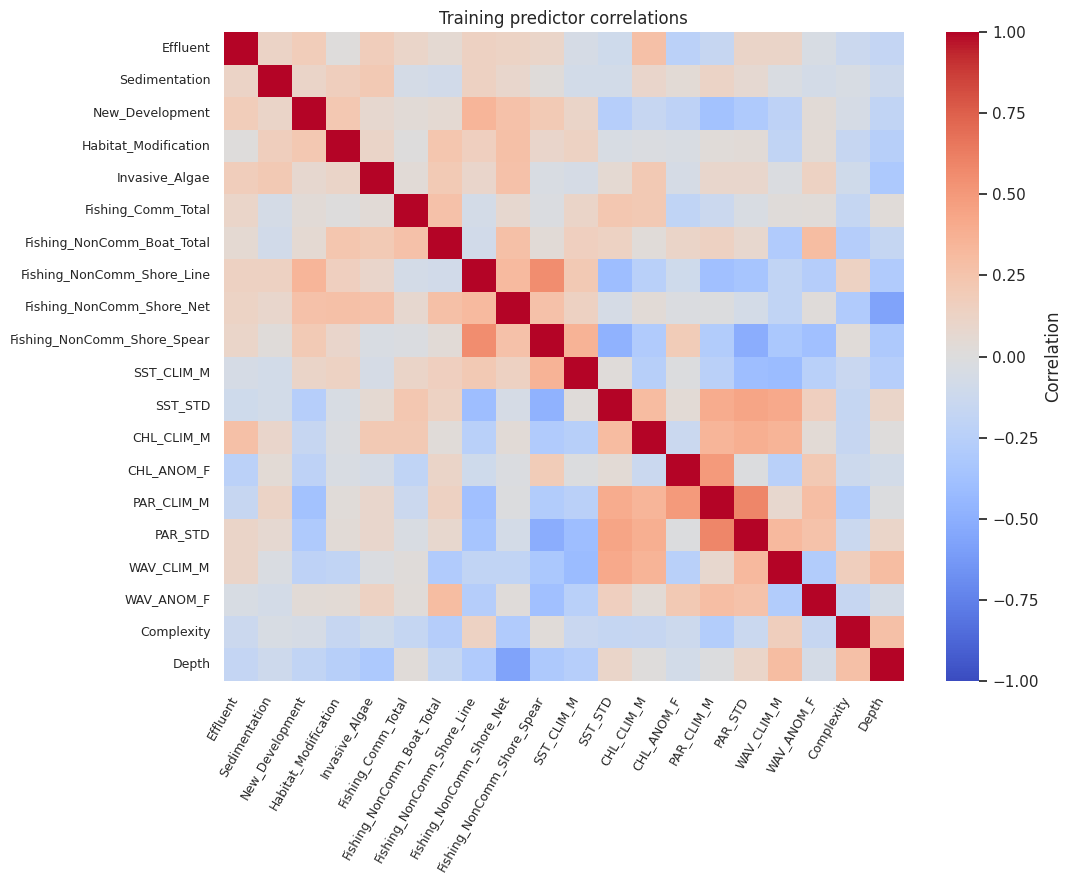

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print('Training:', X_train.shape, '| Test:', X_test.shape)
display(y_train.value_counts().sort_index().rename('Training class counts'))
plt.figure(figsize=(7, 3))
y_train.value_counts().sort_index().plot.bar(title='Training reef regimes')
plt.ylabel('Number of reefs'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11, 9))
sns.heatmap(X_train.corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, cbar_kws={'label':'Correlation'})
plt.xticks(rotation=60, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.title('Training predictor correlations'); plt.tight_layout(); plt.show()

## 3. Missing data and the five engineered features
  

In [4]:
class ClusterImputer(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=8):
        self.n_clusters = n_clusters

    def fit(self, X, y=None):
        a = np.asarray(X, dtype=float)
        self.targets_ = [FEATURES.index('Complexity'), FEATURES.index('Depth')]
        self.other_ = [i for i in range(a.shape[1]) if i not in self.targets_]
        self.mean_ = SimpleImputer(strategy='mean').fit(a)
        self.scale_ = StandardScaler().fit(self.mean_.transform(a)[:, self.other_])
        z = self.scale_.transform(self.mean_.transform(a)[:, self.other_])
        self.kmeans_ = KMeans(n_clusters=self.n_clusters, n_init=10, random_state=SEED).fit(z)
        self.cluster_means_ = np.tile(self.mean_.statistics_, (self.n_clusters, 1))
        for k in range(self.n_clusters):
            for j in self.targets_:
                values = a[self.kmeans_.labels_ == k, j]
                values = values[np.isfinite(values)]
                if len(values):
                    self.cluster_means_[k, j] = values.mean()
        return self

    def transform(self, X):
        a = np.asarray(X, dtype=float)
        out = self.mean_.transform(a)
        groups = self.kmeans_.predict(self.scale_.transform(out[:, self.other_]))
        for j in self.targets_:
            missing = np.isnan(a[:, j])
            out[missing, j] = self.cluster_means_[groups[missing], j]
        return out

def engineer(a):
    a = np.asarray(a, dtype=float)
    def col(name): return a[:, FEATURES.index(name)]
    wave = np.maximum(col('WAV_CLIM_M'), 1e-8)
    depth = np.maximum(col('Depth'), 1e-8)
    complexity = np.maximum(col('Complexity') + 1, 1e-8)
    extra = np.column_stack([
        np.sqrt(wave * complexity), np.log(wave / depth), complexity / depth,
        col('Invasive_Algae') * col('PAR_CLIM_M'), col('WAV_ANOM_F') * col('CHL_ANOM_F')])
    return np.column_stack([a, extra])

class FeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): return self
    def transform(self, X): return engineer(X)

EXTRA = ['sqrt_wave_complexity', 'log_wave_depth', 'complexity_depth',
         'algae_irradiance', 'wave_chlorophyll_anomalies']

### Check imputation on artificially hidden training values
Hide 20% of observed complexity values in an internal validation subset. Compare mean, Lasso and K-means with RMSE (lower is better). This checks plausibility, but artificial missingness may differ from the real missingness. Fixed settings keep the exercise simple; this check does not access the reef-classification test set.

In [5]:
imp_train, imp_val = train_test_split(X_train, test_size=0.2, random_state=SEED)
j = FEATURES.index('Complexity')
known = np.flatnonzero(imp_val.Complexity.notna().to_numpy())
hidden = np.random.default_rng(SEED).choice(known, max(1, len(known)//5), replace=False)
masked = imp_val.copy()
truth = masked.iloc[hidden, j].to_numpy()
masked.iloc[hidden, j] = np.nan
rmse_rows = []
for name, imputer in [('Mean', SimpleImputer(strategy='mean')), ('K-means', ClusterImputer())]:
    predicted = imputer.fit(imp_train).transform(masked)[hidden, j]
    rmse_rows.append((name, np.sqrt(mean_squared_error(truth, predicted))))
other = [c for c in FEATURES if c != 'Complexity']
observed = imp_train.Complexity.notna()
lasso = Pipeline([('impute', SimpleImputer()), ('scale', StandardScaler()),
                  ('model', Lasso(alpha=0.01, max_iter=10000))])
lasso.fit(imp_train.loc[observed, other], imp_train.loc[observed, 'Complexity'])
rmse_rows.append(('Lasso', np.sqrt(mean_squared_error(truth, lasso.predict(masked.iloc[hidden][other])))))
display(pd.DataFrame(rmse_rows, columns=['Imputation', 'Complexity RMSE']).sort_values('Complexity RMSE'))

,Imputation,Complexity RMSE
2,Lasso,4.497837
1,K-means,4.895032
0,Mean,5.571457


## 4. Train and compare models

Majority class → 0.272
Logistic: dropped NA → 0.625
Logistic: mean → 0.619
Logistic: K-means → 0.611
Logistic: regularized → 0.617
Logistic: engineered → 0.621
SVM RBF: original → 0.677
SVM polynomial: original → 0.627
Random forest: original → 0.688
Gradient boosting: original → 0.671
SVM RBF: engineered → 0.678
SVM polynomial: engineered → 0.627
Random forest: engineered → 0.684
Gradient boosting: engineered → 0.673


,Model,Training rows,Train F1,CV micro-F1,CV std,CV macro-F1,Parameters
0,Random forest: original,496,0.980,0.688,0.058,0.684,"{'model__max_depth': 8, 'model__min_samples_le..."
1,Random forest: engineered,496,0.983,0.684,0.052,0.682,"{'model__max_depth': 8, 'model__min_samples_le..."
2,SVM RBF: engineered,496,0.922,0.678,0.045,0.678,"{'model__C': 10, 'model__gamma': 'scale'}"
3,SVM RBF: original,496,0.904,0.677,0.026,0.676,"{'model__C': 10, 'model__gamma': 'scale'}"
4,Gradient boosting: engineered,496,0.985,0.673,0.023,0.669,"{'model__max_depth': 2, 'model__n_estimators':..."
5,Gradient boosting: original,496,0.934,0.671,0.036,0.668,"{'model__max_depth': 2, 'model__n_estimators':..."
6,SVM polynomial: original,496,0.776,0.627,0.031,0.620,"{'model__C': 1, 'model__degree': 3}"
7,SVM polynomial: engineered,496,0.781,0.627,0.028,0.621,"{'model__C': 1, 'model__degree': 3}"
8,Logistic: dropped NA,398,0.708,0.625,0.046,0.624,{}
9,Logistic: engineered,496,0.676,0.621,0.023,0.613,{'model__C': 0.1}


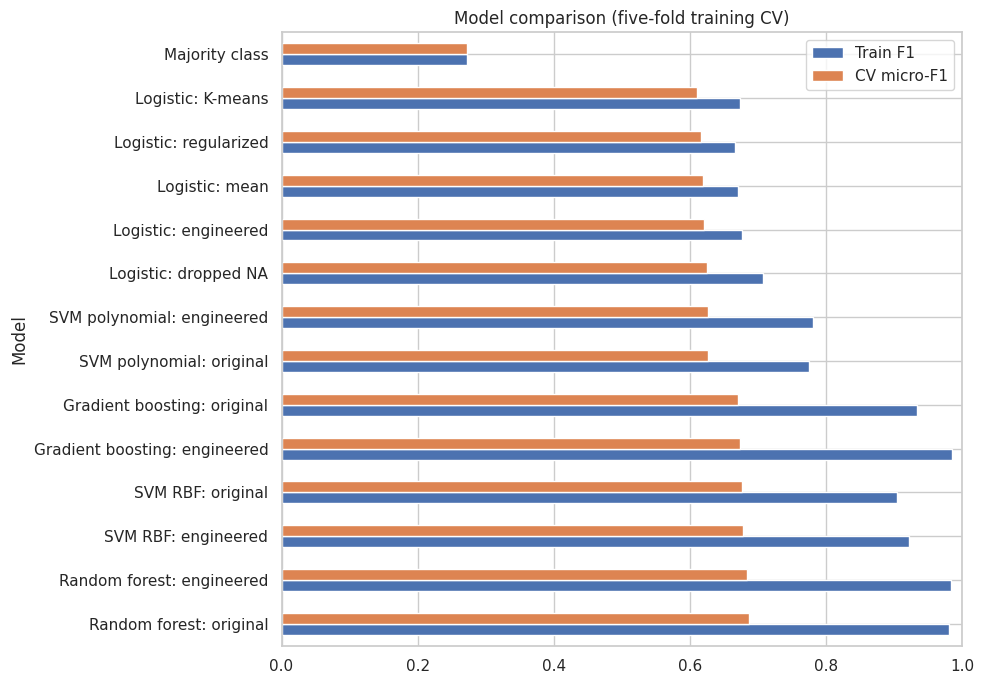

In [6]:
def make_pipeline(model, imputation='cluster', features=False, scale=False):
    steps = [('impute', ClusterImputer() if imputation == 'cluster' else SimpleImputer(strategy='mean'))]
    if features: steps.append(('features', FeatureEngineer()))
    if scale: steps.append(('scale', StandardScaler()))
    return Pipeline(steps + [('model', model)])

logistic = lambda: LogisticRegression(max_iter=3000, solver='lbfgs')
specs = [
    ('Majority class', DummyClassifier(strategy='most_frequent'), 'mean', False, False, {}, False),
    ('Logistic: dropped NA', logistic(), 'mean', False, True, {}, True),
    ('Logistic: mean', logistic(), 'mean', False, True, {}, False),
    ('Logistic: K-means', logistic(), 'cluster', False, True, {}, False),
    ('Logistic: regularized', logistic(), 'cluster', False, True, {'model__C':[0.01, 0.1, 1, 10]}, False),
    ('Logistic: engineered', logistic(), 'cluster', True, True, {'model__C':[0.1, 1, 10]}, False),
]
for engineered in [False, True]:
    suffix = 'engineered' if engineered else 'original'
    specs += [
        ('SVM RBF: '+suffix, SVC(kernel='rbf'), 'cluster', engineered, True,
         {'model__C':[1, 10], 'model__gamma':['scale', 0.01]}, False),
        ('SVM polynomial: '+suffix, SVC(kernel='poly'), 'cluster', engineered, True,
         {'model__C':[0.1, 1], 'model__degree':[2, 3]}, False),
        ('Random forest: '+suffix, RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=1),
         'cluster', engineered, False, {'model__max_depth':[None, 8], 'model__min_samples_leaf':[1, 3]}, False),
        ('Gradient boosting: '+suffix, GradientBoostingClassifier(random_state=SEED),
         'cluster', engineered, False, {'model__n_estimators':[100, 150], 'model__max_depth':[1, 2]}, False)]

searches, rows = {}, []
for name, model, imputation, features, scale, grid, drop_na in specs:
    keep = X_train.notna().all(axis=1) if drop_na else pd.Series(True, index=X_train.index)
    xx, yy = X_train.loc[keep], y_train.loc[keep]
    search = GridSearchCV(make_pipeline(model, imputation, features, scale), grid,
        scoring={'micro':'f1_micro', 'macro':'f1_macro'}, refit='micro', cv=cv,
        return_train_score=True, n_jobs=1, error_score='raise')
    search.fit(xx, yy)
    searches[name] = search
    i = search.best_index_
    rows.append({'Model':name, 'Training rows':len(xx),
        'Train F1':search.cv_results_['mean_train_micro'][i],
        'CV micro-F1':search.cv_results_['mean_test_micro'][i],
        'CV std':search.cv_results_['std_test_micro'][i],
        'CV macro-F1':search.cv_results_['mean_test_macro'][i],
        'Parameters':str(search.best_params_)})
    print(name, '→', round(search.best_score_, 3))
results = pd.DataFrame(rows).sort_values('CV micro-F1', ascending=False).reset_index(drop=True)
display(results.round(3))
results.plot.barh(x='Model', y=['Train F1', 'CV micro-F1'], figsize=(10, 7), xlim=(0, 1))
plt.title('Model comparison (five-fold training CV)'); plt.tight_layout(); plt.show()

## 5. Logistic error analysis using training out-of-fold predictions

,Confidence,Accuracy,Count
Bin,,,
"(0.2, 0.4]",0.362650,0.344828,58
"(0.4, 0.6]",0.490752,0.529703,202
"(0.6, 0.8]",0.692076,0.703704,135
"(0.8, 1.0]",0.871448,0.831683,101


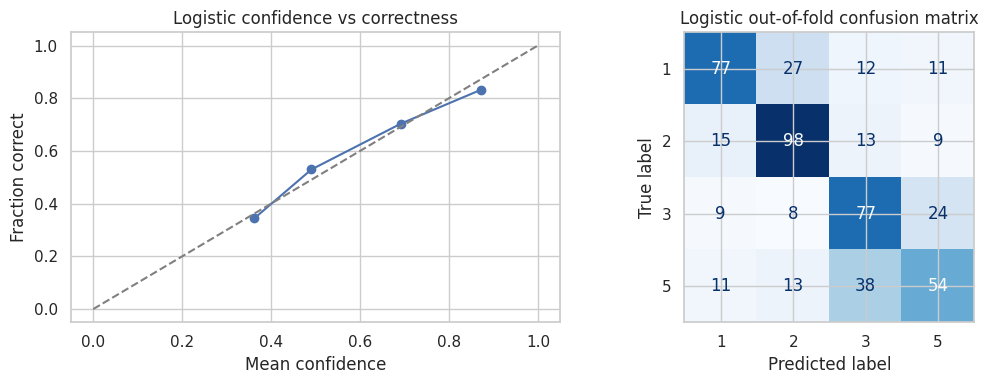

,Count,Accuracy
Actual,,
1,40,0.800000
2,37,0.891892
3,4,0.250000
5,18,0.888889


Most confident errors:


,Actual,Predicted,Confidence,Correct,Bin
195,1,5,0.983835,False,"(0.8, 1.0]"
84,1,5,0.966067,False,"(0.8, 1.0]"
290,3,2,0.925118,False,"(0.8, 1.0]"
356,2,1,0.914640,False,"(0.8, 1.0]"
488,1,2,0.901396,False,"(0.8, 1.0]"
283,1,2,0.883031,False,"(0.8, 1.0]"
88,2,1,0.880060,False,"(0.8, 1.0]"
103,2,1,0.869497,False,"(0.8, 1.0]"
441,1,2,0.854505,False,"(0.8, 1.0]"
170,2,1,0.847398,False,"(0.8, 1.0]"


In [7]:
log_model = searches['Logistic: regularized'].best_estimator_
proba = cross_val_predict(log_model, X_train, y_train, cv=cv, method='predict_proba')
classes = np.sort(y_train.unique())
pred = classes[proba.argmax(axis=1)]
confidence = proba.max(axis=1)
analysis = pd.DataFrame({'Actual':y_train.to_numpy(), 'Predicted':pred,
                         'Confidence':confidence, 'Correct':pred == y_train.to_numpy()})
analysis['Bin'] = pd.cut(confidence, bins=np.linspace(0, 1, 6), include_lowest=True)
bins = analysis.groupby('Bin', observed=True).agg(Confidence=('Confidence','mean'),
                                               Accuracy=('Correct','mean'), Count=('Correct','size'))
display(bins)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(bins.Confidence, bins.Accuracy, 'o-'); axes[0].plot([0,1], [0,1], '--', color='gray')
axes[0].set(xlabel='Mean confidence', ylabel='Fraction correct', title='Logistic confidence vs correctness')
ConfusionMatrixDisplay.from_predictions(y_train, pred, labels=classes, ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Logistic out-of-fold confusion matrix'); plt.tight_layout(); plt.show()
display(analysis.nlargest(max(1, len(analysis)//5), 'Confidence').groupby('Actual').agg(
    Count=('Correct','size'), Accuracy=('Correct','mean')))
print('Most confident errors:')
display(analysis.loc[~analysis.Correct].nlargest(10, 'Confidence'))

## 6. PCA visualization


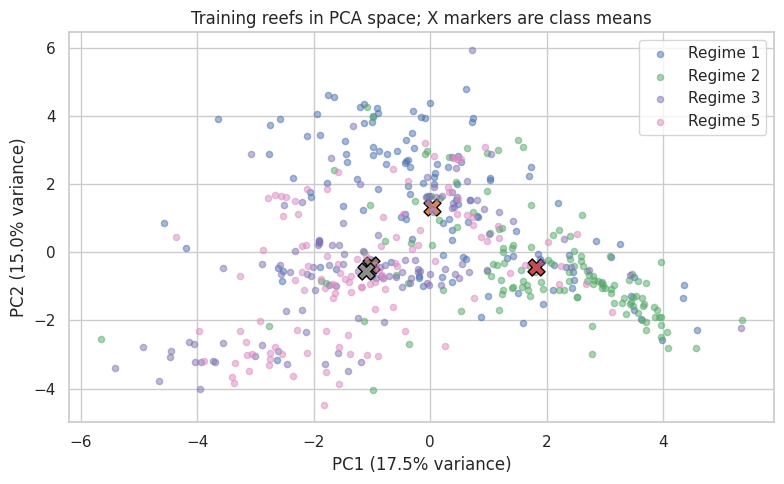

In [8]:
pca_imputer = ClusterImputer().fit(X_train)
engineered_train = engineer(pca_imputer.transform(X_train))
scaled_train = StandardScaler().fit_transform(engineered_train)
pca = PCA(n_components=2)
coords = pca.fit_transform(scaled_train)
plt.figure(figsize=(8, 5))
for regime in classes:
    group = coords[y_train.to_numpy() == regime]
    plt.scatter(group[:,0], group[:,1], alpha=0.5, s=20, label=f'Regime {regime}')
    plt.scatter(*group.mean(axis=0), marker='X', s=150, edgecolors='black')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.title('Training reefs in PCA space; X markers are class means')
plt.legend(); plt.tight_layout(); plt.show()

## 7. Evaluate the selected model once on the test set


Selected model: Random forest: original
Test micro-F1 / accuracy: 0.734
Test macro-F1: 0.719
              precision    recall  f1-score   support

           1       0.83      0.80      0.81        44
           2       0.71      0.73      0.72        37
           3       0.64      0.64      0.64        25
           5       0.68      0.72      0.70        18

    accuracy                           0.73       124
   macro avg       0.72      0.72      0.72       124
weighted avg       0.74      0.73      0.73       124



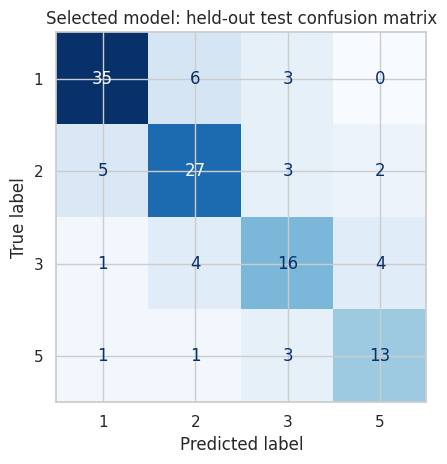

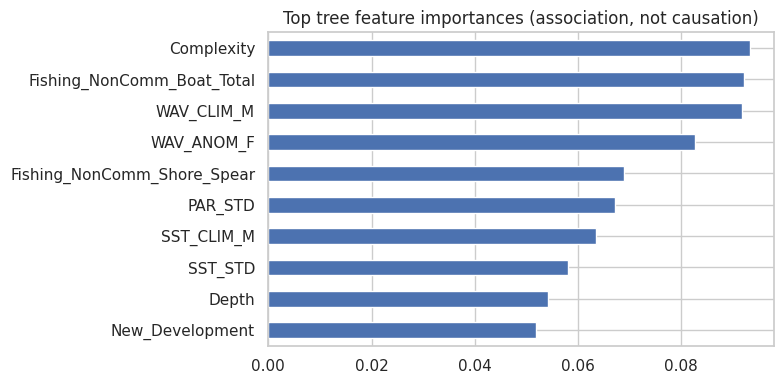

In [9]:
eligible = results.loc[~results.Model.isin(['Majority class', 'Logistic: dropped NA'])]
best_name = eligible.iloc[0].Model
best_model = searches[best_name].best_estimator_
test_pred = best_model.predict(X_test)
test_micro = f1_score(y_test, test_pred, average='micro')
test_macro = f1_score(y_test, test_pred, average='macro')
print('Selected model:', best_name)
print(f'Test micro-F1 / accuracy: {test_micro:.3f}')
print(f'Test macro-F1: {test_macro:.3f}')
assert np.isclose(test_micro, accuracy_score(y_test, test_pred))
print(classification_report(y_test, test_pred, labels=classes, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=classes, cmap='Blues', colorbar=False)
plt.title('Selected model: held-out test confusion matrix'); plt.tight_layout(); plt.show()
if hasattr(best_model.named_steps['model'], 'feature_importances_'):
    names = FEATURES + (EXTRA if 'features' in best_model.named_steps else [])
    pd.Series(best_model.named_steps['model'].feature_importances_, index=names).nlargest(10).sort_values().plot.barh(figsize=(8,4))
    plt.title('Top tree feature importances (association, not causation)'); plt.tight_layout(); plt.show()

## 8. Compare with the paper and save your results

In [10]:
paper_rows = [
    ('Logistic: dropped NA', 0.60), ('Logistic: mean', 0.66), ('Logistic: K-means', 0.64),
    ('Logistic: regularized', 0.62), ('Logistic: engineered', 0.62),
    ('SVM RBF: engineered', 0.65), ('SVM polynomial: engineered', 0.61),
    ('Random forest: engineered', 0.70), ('Gradient boosting: engineered', 0.69)]
comparison = pd.DataFrame(paper_rows, columns=['Model', 'Paper CV micro-F1']).merge(
    results[['Model','CV micro-F1']], on='Model', how='left')
comparison['Difference'] = comparison['CV micro-F1'] - comparison['Paper CV micro-F1']
display(comparison.round(3))
print(f'Our selected model: {best_name}; CV = {eligible.iloc[0]["CV micro-F1"]:.3f}; test = {test_micro:.3f}.')
print('Paper reference: engineered random forest CV = 0.70, test micro-F1 = 0.70.')
results.to_csv('model_comparison.csv', index=False)
comparison.to_csv('paper_comparison.csv', index=False)
pd.DataFrame({'Actual':y_test, 'Predicted':test_pred}).to_csv('test_predictions.csv', index_label='Dataset row')
print('Saved three CSV files in the current runtime. In Colab, download them from the Files panel if needed.')

,Model,Paper CV micro-F1,CV micro-F1,Difference
0,Logistic: dropped NA,0.60,0.625,0.025
1,Logistic: mean,0.66,0.619,-0.041
2,Logistic: K-means,0.64,0.611,-0.029
3,Logistic: regularized,0.62,0.617,-0.003
4,Logistic: engineered,0.62,0.621,0.001
5,SVM RBF: engineered,0.65,0.678,0.028
6,SVM polynomial: engineered,0.61,0.627,0.017
7,Random forest: engineered,0.70,0.684,-0.016
8,Gradient boosting: engineered,0.69,0.673,-0.017


Our selected model: Random forest: original; CV = 0.688; test = 0.734.
Paper reference: engineered random forest CV = 0.70, test micro-F1 = 0.70.
Saved three CSV files in the current runtime. In Colab, download them from the Files panel if needed.


## 9. Explain the project in your own words
After running, use the computed scores above to answer:
1. Which model had the highest CV score? Did its test score remain similar?
2. Did adding the five features help each nonlinear model?
3. Which regime had the weakest recall? How well was degraded regime 1 detected?
4. Is there a large train/CV gap suggesting overfitting?
5. What information is lost in the PCA plot?

**Limitations:** small dataset; spatial dependence; labels produced by a previous clustering study; limited tuning; uncertain real missingness patterns. Random splitting measures performance on held-out reefs in this dataset, not future climate conditions. Correlation and feature importance do not establish causal effects.

**References:**
- Cheng, T., Murphy, A., and Walecka, S. (2019). [Predicting Coral Reef Regimes from Human and Natural Influences](https://cs229.stanford.edu/proj2019spr/report/56.pdf).
- [Authors' source code, original data and feature formulas](https://github.com/salliewalecka/Hawaii_RegimesPredictors).


## Observations from the verified run
The original-feature random forest won with CV micro-F1 **0.688**, followed closely by its engineered counterpart (**0.684**). Its held-out micro-F1 was **0.734** and macro-F1 **0.719**. Regime 1 recall was **0.795**; regime 3 had the lowest recall (**0.640**). The winner's mean training-fold score (**0.980**) was much higher than CV, indicating overfitting even though the held-out score was reasonable. Engineered features gave small gains for some models, but did not consistently help. Re-running under different library versions may change these measured values. These observations describe the saved run, not the paper's results.